# Figur 1 · Hvad lovede partierne?

**Underspørgsmål 1.** Figuren har tre dele, der svarer på hver sin del af spørgsmålet:

- **Panel a: hvilke emner** lovede hvert parti noget om? (andel mærkesager pr. kategori)
- **Panel b: hvad lovede de konkret?** (de ord, der er mest karakteristiske for hvert partis program, TF-IDF)
- **Panel c (valgfri): hvem lovede det samme?** (tekstnetværk). Kan flyttes til figur 3, hvis pladsen mangler.

Til sidst laves en tabel med alle mærkesagernes titler til Methods eller appendiks.

I tekstnetværket er noder de 11 partier. En kant betyder, at to partiers mærkesager (Wayback-snapshots, senest 31. oktober 2022) ligner hinanden i ordvalg, målt med TF-IDF og cosine-lighed. For at undgå en hårbold beholder vi hvert partis *k* stærkeste forbindelser (backbone, uge 4).

**Hvad målet fanger:** fælles ordforråd i programmerne.
**Hvad det ikke fanger:** om partierne er *enige*. To partier kan bruge de samme ord om kriminalitet og mene det modsatte.

Notebooken forventer at ligge i `notebooks/`, så data findes i `../data/`.

In [53]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from matplotlib.ticker import PercentFormatter

In [54]:


MAPPE = "../data/"
PARTIER = ["S", "V", "M", "SF", "DD", "LA", "KF", "EL", "DF", "RV", "ALT", "NB"]
REGERING = {"S", "V", "M"}
FARVER = {"S": "#E32F3B", "V": "#254264", "M": "#B48CD2", "SF": "#E07EA8", "DD": "#7896D2",
          "LA": "#3FB2BE", "KF": "#5C8A3A", "EL": "#E6801A", "DF": "#EAC73E", "RV": "#733280", "ALT": "#2B8738", "NB": "#4495FF"}

## 1 · Indlæs og filtrér

In [55]:
pol = pd.read_csv("../../data/maerkesager_klassificeret.csv", encoding="utf-8-sig")
pol = pol[pol["party_code"].isin(PARTIER) & (pol["kategori"] != "Andet")].copy()

print(len(pol), "mærkesager")
pol["party_code"].value_counts().reindex(PARTIER)

3159 mærkesager


party_code
S      622
V      158
M       99
SF     300
DD      60
LA     131
KF     149
EL      49
DF     291
RV     372
ALT    122
NB     806
Name: count, dtype: int64

## 2 · Stopord

Jeres egen liste (journalist-, fyldord og politikernavne) plus almindelige danske småord, som ellers dominerer i rå tekst.

In [56]:
custom_stopwords = [
    # Journalist- og citatord
    "sige", "mene", "udtale", "spørge", "svare", "fortælle", "kalde", "pege",
    # Talesprogs-fyldord
    "helt", "rigtig", "faktisk", "selvfølgelig", "god", "godt", "stor", "stort",
    "hel", "få", "gå", "tage", "se", "give", "komme", "blive", "gøre", "kunne",
    "ville", "skulle", "måtte", "når", "hvor", "hvordan", "fordi", "også", "bare",
    "lidt", "meget", "mange", "flere", "ny", "nyt", "nye", "dansk", "danmark",
    "parti", "partier", "politik", "politisk", "valgkamp", "valg", "folketingsvalg",
    "folk", "ting", "sag", "måde", "dag", "år", "gang", "tid", "del", "spørgsmål",
    "mette", "frederiksen", "lars", "løkke", "rasmussen", "jakob", "ellemann",
    "jensen", "søren", "pape", "poulsen", "pia", "olsen", "dyhr", "inger", "støjberg",
    "alex", "vanopslagh", "sofie", "carsten", "nielsen", "mai", "villadsen",
    "morten", "messerschmidt", "pernille", "vermund", "franciska", "rosenkilde"
]

smaaord = """og i at det en den til er som på de med han af for ikke der var mig sig men et har om vi
min havde ham hun nu over da fra du ud sin dem os op man hans hvor eller hvad skal selv her alle vil
blev kunne ind når være dog noget ville jo deres efter ned skulle denne end dette mit også under have
dig anden hende mine alt meget sit sine vor mod disse hvis din nogle hos blive mange ad bliver hendes
været thi jer sådan vores flere kan får gøre mere mindre derfor både hele sammen igennem uden andre
andet ved fordi danskerne""".split()

# Talord, fyldord og partinavne, som checket i afsnit 9 viste dominerer uden at sige noget om indholdet
ekstra = ["mio", "mia", "pct", "kr", "støtte", "stop", "giv", "ligeledes", "forskellige", "generelt",
          "socialdemokratiet", "venstre", "moderaterne", "enhedslisten", "alternativet", "radikale",
          "folkeparti", "danmarksdemokraterne", "konservative", "liberal", "alliance", "christiansborg",
          "nødt", "rigtigt", "sættes", "politikområder", "mærkesager", "ordfører", "foreslå", "læs",
          "indgået", "forslaget", "ugers", "virkeligheden", "nej", "pas", "tjener"]

STOPORD = set(smaaord) | set(custom_stopwords) | set(ekstra)
print(len(STOPORD), "stopord")


def tokenize(tekst):
    ord_ = re.findall(r"[a-zæøåé]+", tekst.lower())
    return [w for w in ord_ if len(w) > 2 and w not in STOPORD]

226 stopord


## 3 · Ét dokument pr. parti og TF-IDF

- `min_df=2`: et ord skal bruges af mindst to partier, ellers kan det ikke gøre to partier ens.
- `max_df=0.9`: ord, som næsten alle partier bruger, fjernes.
- `sublinear_tf=True`: et ord, der gentages mange gange, vejer ikke uforholdsmæssigt meget.

In [57]:
docs = pol.groupby("party_code")["text"].apply(" ".join).reindex(PARTIER)

vec = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None,
                      min_df=2, max_df=0.9, sublinear_tf=True)
X = vec.fit_transform(docs)
print(X.shape[0], "partier,", X.shape[1], "ord i ordforrådet")

S = cosine_similarity(X)
np.fill_diagonal(S, np.nan)          # et parti ligner altid sig selv 100 %
sim = pd.DataFrame(S, index=PARTIER, columns=PARTIER)

# de mest lignende par
par = sim.where(np.triu(np.ones(sim.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print(par.head(8).round(3))

12 partier, 3155 ord i ordforrådet
S   NB    0.495
DF  NB    0.458
SF  NB    0.445
RV  NB    0.436
S   DF    0.400
    SF    0.396
    RV    0.390
SF  RV    0.375
dtype: float64


## 4 · Panel a: hvilke emner lovede de noget om?

`normalize="index"` gør, at hver række summer til 1, så partier med mange og få sider kan sammenlignes. Antal sider står ved partiet, fordi 4 sider er et tyndt grundlag.

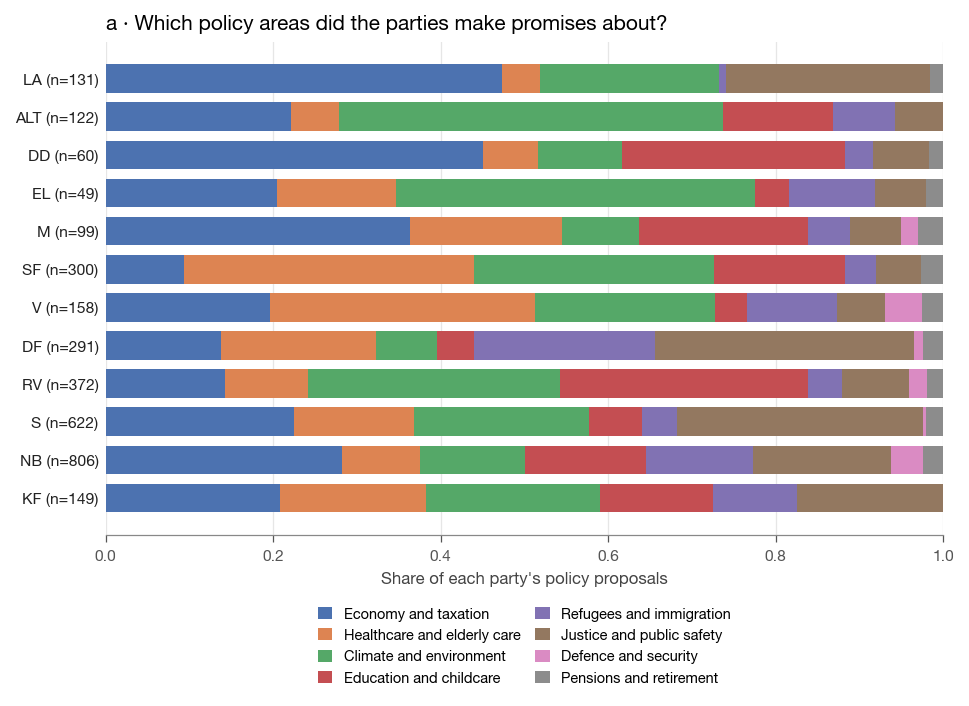

kategori    Økonomi og skat  Sundhed og ældrepleje  Klima og miljø  \
party_code                                                           
S                  0.225080               0.143087        0.209003   
V                  0.196203               0.316456        0.215190   
M                  0.363636               0.181818        0.090909   
SF                 0.093333               0.346667        0.286667   
DD                 0.450000               0.066667        0.100000   
LA                 0.473282               0.045802        0.213740   
KF                 0.208054               0.174497        0.208054   
EL                 0.204082               0.142857        0.428571   
DF                 0.137457               0.185567        0.072165   
RV                 0.142473               0.099462        0.301075   
ALT                0.221311               0.057377        0.459016   
NB                 0.281638               0.093052        0.126551   

kategori    Skoler 

In [58]:
KATEGORIER = ["Økonomi og skat", "Sundhed og ældrepleje", "Klima og miljø", "Skoler og børnepasning",
              "Flygtninge og indvandrere", "Retspolitik og tryghed", "Forsvar og sikkerhed", "Pension og tilbagetrækning"]

CATEGORY_EN = {
    "Økonomi og skat": "Economy and taxation",
    "Sundhed og ældrepleje": "Healthcare and elderly care",
    "Klima og miljø": "Climate and environment",
    "Skoler og børnepasning": "Education and childcare",
    "Flygtninge og indvandrere": "Refugees and immigration",
    "Retspolitik og tryghed": "Justice and public safety",
    "Forsvar og sikkerhed": "Defence and security",
    "Pension og tilbagetrækning": "Pensions and retirement"
}
KAT_FARVER = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C"]

andel = pd.crosstab(pol["party_code"], pol["kategori"], normalize="index").reindex(index=PARTIER, columns=KATEGORIER, fill_value=0)
antal = pol["party_code"].value_counts()
raekkefoelge = list(andel.max(axis=1).sort_values().index)      # mest fokuserede parti nederst


def tegn_panel_a(ax):
    venstre = np.zeros(len(raekkefoelge))
    for kat, farve in zip(KATEGORIER, KAT_FARVER):
        v = andel.loc[raekkefoelge, kat].values
        ax.barh(
    range(len(raekkefoelge)),
    v,
    left=venstre,
    color=farve,
    height=0.75,
    label=CATEGORY_EN[kat]
)
        venstre += v
    ax.set_yticks(range(len(raekkefoelge)), [f"{p} (n={antal[p]})" for p in raekkefoelge])
    ax.set_xlabel("Share of each party's policy proposals")
    ax.set_title("a · Which policy areas did the parties make promises about?",
             fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=7, frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))


fig, ax = plt.subplots(figsize=(6.5, 4.8)); tegn_panel_a(ax); plt.tight_layout(); plt.show()

#print df policy from graph
print(andel)

# Hvor præcist er det

In [60]:
DATA = "../../data/"

# Indlæs valideringsresultater pr. kategori
validation_results = pd.read_csv(
    DATA + "policy_validation_results.csv"
    
)

# Indlæs samlede valideringsresultater
validation_summary = pd.read_csv(
    DATA + "policy_validation_summary.csv"
).iloc[0]

display(validation_results)
display(validation_summary)

,category,precision,recall,f1,support,predicted_count
0,Sundhed og ældrepleje,0.857143,0.705882,0.774194,17,14
1,Klima og miljø,0.933333,0.736842,0.823529,19,15
2,Skoler og børnepasning,0.875000,0.700000,0.777778,10,8
3,Økonomi og skat,0.894737,0.515152,0.653846,33,19
4,Flygtninge og indvandrere,1.000000,1.000000,1.000000,4,4
5,Retspolitik og tryghed,0.500000,0.571429,0.533333,7,8
6,Forsvar og sikkerhed,1.000000,1.000000,1.000000,1,1
7,Pension og tilbagetrækning,0.500000,1.000000,0.666667,1,2


n_segments         120.000000
micro_precision      0.845070
micro_recall         0.652174
micro_f1             0.736196
Name: 0, dtype: float64

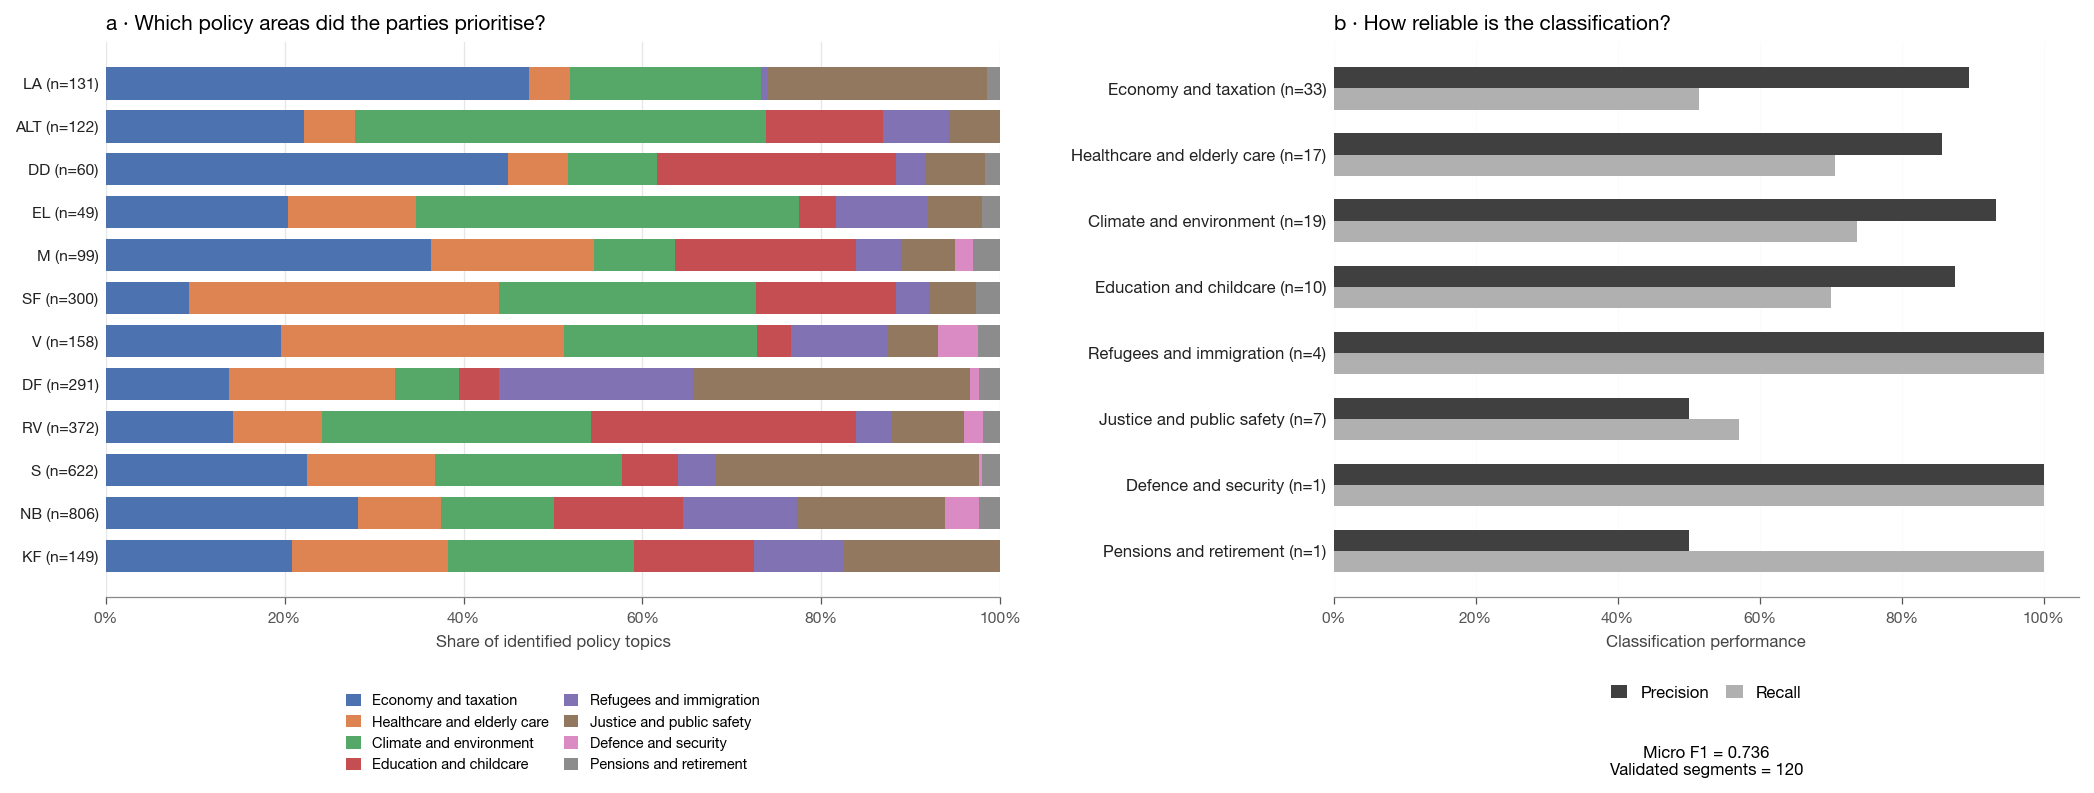

In [61]:

pol_plot = pol[pol["kategori"].isin(KATEGORIER)].copy()

andel = pd.crosstab(
    pol_plot["party_code"],
    pol_plot["kategori"],
    normalize="index"
).reindex(
    index=PARTIER,
    columns=KATEGORIER,
    fill_value=0
)

antal = pol_plot["party_code"].value_counts()

raekkefoelge = list(
    andel.max(axis=1).sort_values().index
)


# ───────────── Panel A: Politiske prioriteter ─────────────

def tegn_panel_a(ax):

    venstre = np.zeros(len(raekkefoelge))

    for kat, farve in zip(KATEGORIER, KAT_FARVER):

        v = andel.loc[raekkefoelge, kat].values

        ax.barh(
            range(len(raekkefoelge)),
            v,
            left=venstre,
            color=farve,
            height=0.75,
            label=CATEGORY_EN[kat]
        )

        venstre += v

    ax.set_yticks(
        range(len(raekkefoelge)),
        [
            f"{p} (n={antal.get(p, 0)})"
            for p in raekkefoelge
        ]
    )

    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1))

    ax.set_xlabel("Share of identified policy topics")

    ax.set_title(
        "a · Which policy areas did the parties prioritise?",
        fontsize=10,
        loc="left"
    )

    ax.spines[["top", "right"]].set_visible(False)

    ax.legend(
        fontsize=7,
        frameon=False,
        ncol=2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15)
    )


# ───────────── Panel B: Validering ─────────────

def tegn_panel_b(ax):

    results = (
        validation_results
        .set_index("category")
        .reindex(KATEGORIER)
    )

    y = np.arange(len(results))
    height = 0.32

    # Precision
    ax.barh(
        y - height / 2,
        results["precision"],
        height=height,
        color="#404040",
        label="Precision"
    )

    # Recall
    ax.barh(
        y + height / 2,
        results["recall"],
        height=height,
        color="#B0B0B0",
        label="Recall"
    )

    # Vis antal positive referenceeksempler
    ax.set_yticks(
        y,
        [
            f"{CATEGORY_EN[cat]} (n={int(results.loc[cat, 'support'])})"
            for cat in results.index
        ],
        fontsize=8
    )

    ax.invert_yaxis()

    ax.set_xlim(0, 1.05)
    ax.xaxis.set_major_formatter(PercentFormatter(1))

    ax.set_xlabel("Classification performance")

    ax.set_title(
        "b · How reliable is the classification?",
        fontsize=10,
        loc="left"
    )

    ax.spines[["top", "right"]].set_visible(False)

    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

    ax.legend(
        fontsize=8,
        frameon=False,
        ncol=2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.13)    )

    # Samlede valideringsresultater
    ax.text(
        0.5,
        -0.32,
        f"Micro F1 = {validation_summary['micro_f1']:.3f}\n"
        f"Validated segments = {int(validation_summary['n_segments'])}",
        transform=ax.transAxes,
        ha="center",
        fontsize=8
    )


# ───────────── Samlet figur ─────────────

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    gridspec_kw={"width_ratios": [1.2, 1]}
)

tegn_panel_a(axes[0])
tegn_panel_b(axes[1])

plt.tight_layout(w_pad=3)

fig.savefig(
    "fig1_hvad_lover_de_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5 · Panel b: hvad lovede de konkret?

For hvert parti vises de seks ord med højest TF-IDF-vægt (søjlelængde = vægt i forhold til partiets øverste ord): ord, som partiet bruger meget, og som få andre partier bruger. Det er partiets *karakteristiske* løfter, ikke de hyppigste ord.

In [62]:
ORD = np.array(vec.get_feature_names_out())
N_ORD = 6

WORD_TRANSLATIONS = {
    "fængselsbetjente": "prison officers",
    "bandernes": "gangs",
    "banderne": "gangs",
    "kriminalitet": "crime",
    "målet": "the goal",
    "nedbringe": "reduce",
    "drikkevand": "drinking water",
    "klimakampen": "climate action",
    "havvind": "offshore wind",
    "forrest": "at the forefront",
    "regeringen": "government",
    "beskæftigelsesindsats": "employment initiatives",
    "aftale": "agreement",
    "organiseret": "organised",
    "kulturen": "culture",
    "kultur": "culture",
    "velfærden": "welfare",
    "udenlandsk": "foreign",
    "skat": "tax",
    "minimumsnormeringer": "minimum staffing levels",
    "mistrivsel": "poor well-being",
    "tilbud": "services",
    "demens": "dementia",
    "stoffer": "drugs",
    "økologisk": "organic",
    "barsel": "parental leave",
    "faglært": "skilled workers",
    "familierne": "families",
    "erhvervsskolerne": "vocational schools",
    "studerende": "students",
    "elafgiften": "electricity tax",
    "retssikkerheden": "legal protection",
    "skattetryk": "tax burden",
    "borgerne": "citizens",
    "retssikkerhed": "legal protection",
    "skatter": "taxes",
    "dagtilbud": "daycare",
    "loven": "the law",
    "lavere": "lower",
    "praktiserende": "general practitioners",
    "flyttes": "relocated",
    "fair": "fair",
    "ligeløn": "equal pay",
    "ramt": "affected",
    "animalske": "animal-based",
    "hullerne": "the gaps",
    "sæt": "set",
    "reformer": "reforms",
    "rent": "clean",
    "lærere": "teachers",
    "tilliden": "trust",
    "åbenhed": "transparency",
    "landbrug": "agriculture",
    "bæredygtige": "sustainable",
    "mad": "food",
    "jord": "soil",
    "landbrugsjord": "agricultural land",
    "regenerativt": "regenerative",
    "kriminelle": "criminals",
    "marked": "market",
    "statsborgerretskonventionen": "citizenship convention",
    "europæiske": "European"
}


def top_ord(p, n=N_ORD):
    r = X[PARTIER.index(p)].toarray().ravel()
    idx = np.argsort(r)[::-1][:n]

    words = [
        WORD_TRANSLATIONS.get(ORD[i], ORD[i])
        for i in idx
    ]

    return words, list(r[idx])


for p in PARTIER:
    print(f"{p:>3}:", ", ".join(top_ord(p)[0]))

  S: prison officers, gangs, domstolene, gangs, anklagemyndigheden, lokalsamfund
  V: offshore wind, climate action, dementia, gasfyr, employment initiatives, kvinders
  M: kulturlivet, binder, pakkeforløb, culture, forventning, sandet
 SF: organic, minimum staffing levels, arbejdsmiljø, poor well-being, dementia, brugerbetaling
 DD: skilled workers, vocational schools, parental leave, koste, gymnasierne, gymnasiet
 LA: legal protection, elnettet, tax burden, borger, kernekraft, efterligne
 KF: arveafgiften, daycare, forbrydere, tildeling, politibetjente, parallelsamfund
 EL: animal-based, https, klimaneutral, fossilbiler, equal pay, vild
 DF: market, nyhedsbrev, gangs, islamiske, legalisering, konventioner
 RV: culture, poor well-being, folkeskole, bæredygtigt, videreuddannelse, klimaforandringerne
ALT: ejere, videregående, sustainable, folkeafstemning, fonden, agricultural land
 NB: borgerlige, bilen, ændringer, borgerligt, barnet, islam


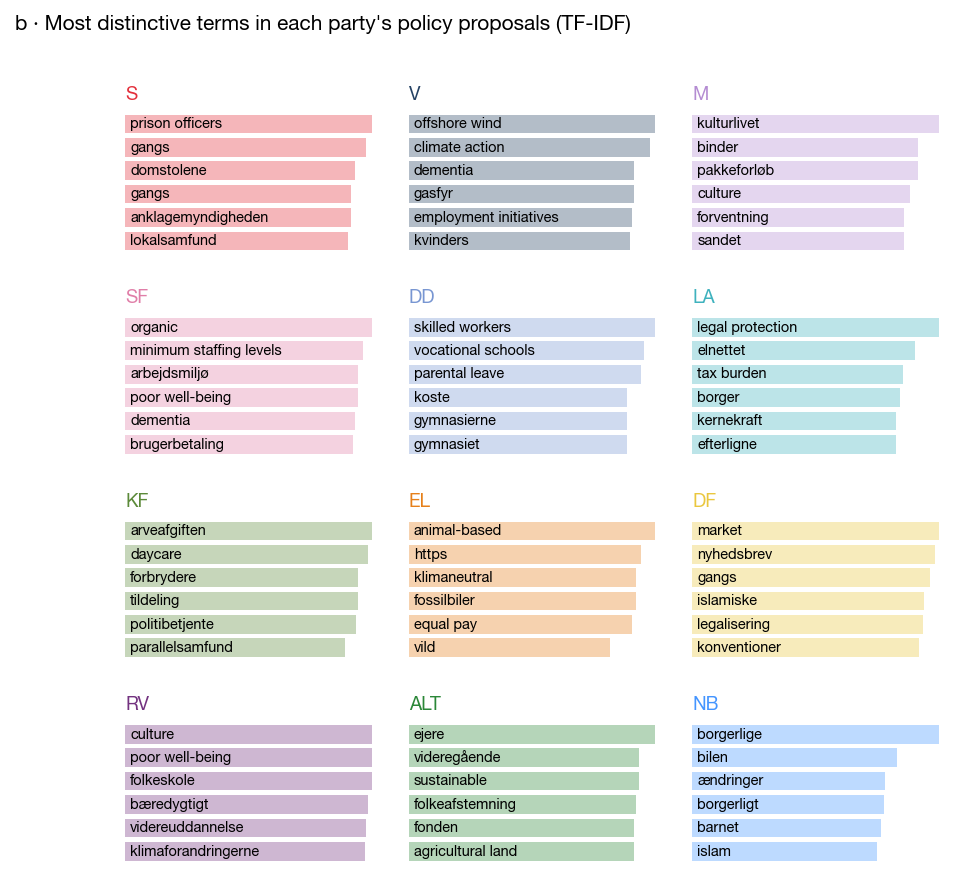

In [63]:
def tegn_panel_b(fig, gs, ncol=3):
    for k, p in enumerate(PARTIER):
        ax = fig.add_subplot(gs[k // ncol, k % ncol])
        ord_, vaegt = top_ord(p)
        vaegt = np.array(vaegt) / max(vaegt)                # relativ vægt inden for partiet
        ax.barh(range(len(ord_)), vaegt, color=FARVER[p], alpha=0.35, height=0.8)
        for i, w in enumerate(ord_):                         # ordet skrives oven på søjlen
            ax.text(0.02, i, w, va="center", ha="left", fontsize=7)
        ax.set_xlim(0, 1); ax.set_ylim(len(ord_) - 0.5, -0.5)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(p, fontsize=9, fontweight="bold", color=FARVER[p], loc="left")
        ax.spines[["top", "right", "bottom", "left"]].set_visible(False)


fig = plt.figure(figsize=(7, 6.5))
gs = fig.add_gridspec(4, 3, hspace=0.45, wspace=0.15)
tegn_panel_b(fig, gs)
fig.suptitle("b · Most distinctive terms in each party's policy proposals (TF-IDF)",fontsize=10, x=0.02, ha="left")
fig.savefig("fig1b_karakteristiske_ord.pdf", bbox_inches="tight")
fig.savefig("fig1b_karakteristiske_ord.png", dpi=300, bbox_inches="tight")
plt.show()

## 6 · Panel c (valgfri): byg tekstnetværket (backbone)

For hvert parti beholder vi de *k* partier, det ligner mest. En kant kommer med, hvis den er blandt *mindst ét* af de to partiers top-*k*. Kantvægt = cosine-lighed.

In [64]:
def tekstnetvaerk(sim, k=3):
    G = nx.Graph()
    G.add_nodes_from(sim.index)
    for p in sim.index:
        for q, w in sim.loc[p].drop(p).nlargest(k).items():
            G.add_edge(p, q, weight=float(w))
    return G


K = 3
G = tekstnetvaerk(sim, K)
print(G.number_of_nodes(), "noder,", G.number_of_edges(), "kanter")
print("Grad pr. parti:", dict(sorted(G.degree(), key=lambda t: -t[1])))

12 noder, 30 kanter
Grad pr. parti: {'S': 11, 'NB': 10, 'RV': 8, 'SF': 6, 'DF': 4, 'V': 3, 'M': 3, 'DD': 3, 'LA': 3, 'KF': 3, 'EL': 3, 'ALT': 3}


## 7 · Tegn panel c

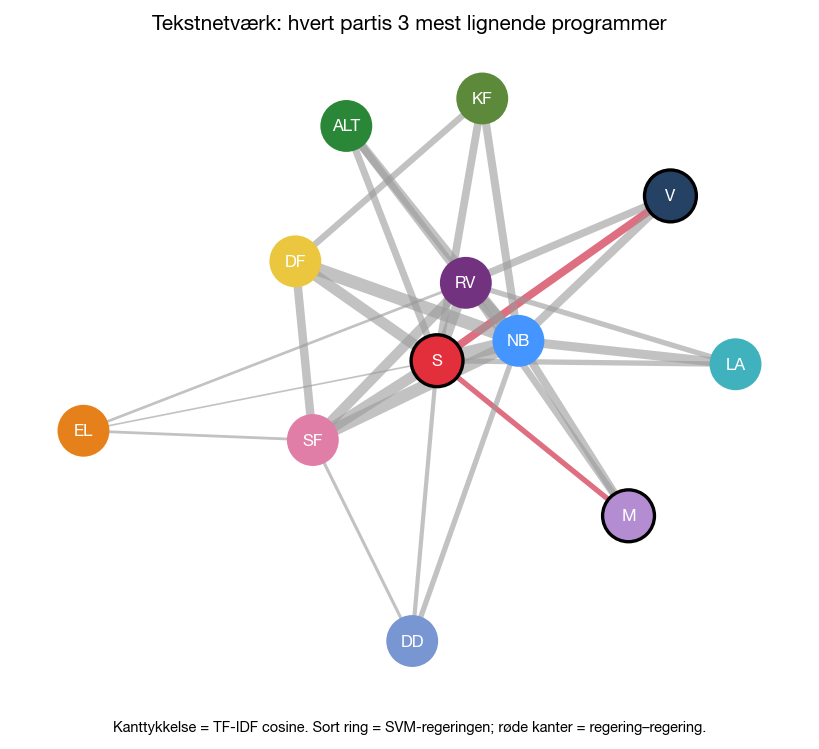

In [65]:
def tegn(G, ax, titel, seed=4):
    pos = nx.spring_layout(G, weight="weight", seed=seed)
    w = np.array([G[u][v]["weight"] for u, v in G.edges()])
    bredde = 0.8 + 6 * (w - w.min()) / (w.max() - w.min() + 1e-9)
    kantfarve = ["#c8102e" if u in REGERING and v in REGERING else "#9a9a9a" for u, v in G.edges()]
    nx.draw_networkx_edges(G, pos, ax=ax, width=bredde, alpha=0.6, edge_color=kantfarve)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[FARVER[p] for p in G], node_size=620,
                           edgecolors=["k" if p in REGERING else "none" for p in G], linewidths=1.6)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_color="white", font_weight="bold")
    ax.set_title(titel, fontsize=10)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(5.5, 5))
tegn(G, ax, f"Tekstnetværk: hvert partis {K} mest lignende programmer")
fig.text(0.5, 0.02, "Kanttykkelse = TF-IDF cosine. Sort ring = SVM-regeringen; røde kanter = regering–regering.",
         ha="center", fontsize=7)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig("fig1c_tekstnetvaerk.pdf", bbox_inches="tight")
fig.savefig("fig1c_tekstnetvaerk.png", dpi=300, bbox_inches="tight")
plt.show()

## 8 · Robusthedscheck: ændrer netværket sig med *k*?

Antallet af kanter er et valg. Hvis strukturen er nogenlunde den samme for k = 2, 3 og 4, kan I skrive det i captionen.

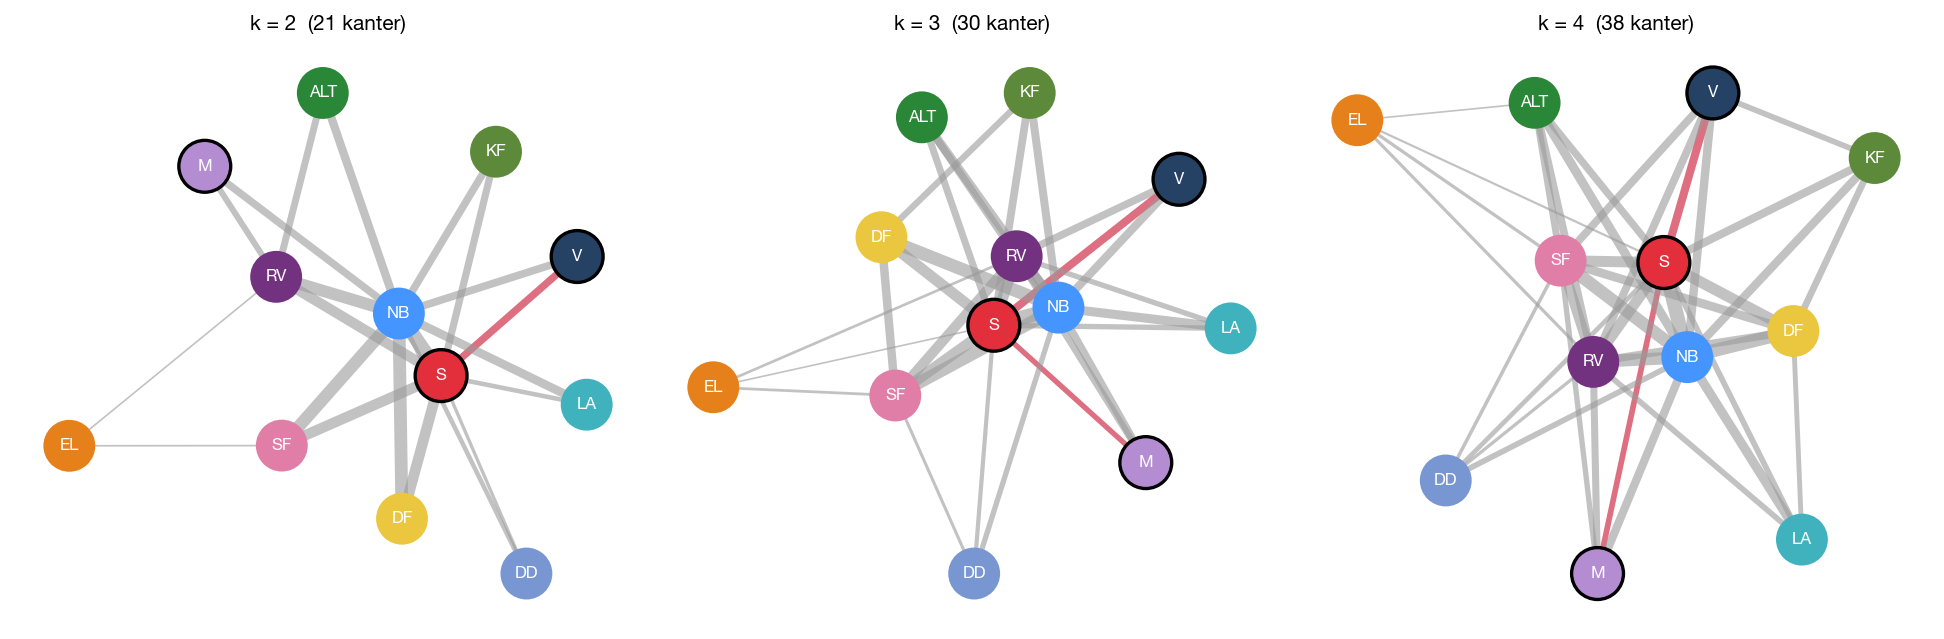

k=2: 21 af 30 kanter fra k=3 går igen
k=4: 30 af 30 kanter fra k=3 går igen


In [66]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, k in zip(axes, [2, 3, 4]):
    Gk = tekstnetvaerk(sim, k)
    tegn(Gk, ax, f"k = {k}  ({Gk.number_of_edges()} kanter)")
plt.tight_layout(); plt.show()

# Hvor mange af k=3-kanterne findes også ved k=2 og k=4?
E3 = {frozenset(e) for e in tekstnetvaerk(sim, 3).edges()}
for k in [2, 4]:
    Ek = {frozenset(e) for e in tekstnetvaerk(sim, k).edges()}
    print(f"k={k}: {len(E3 & Ek)} af {len(E3)} kanter fra k=3 går igen")

## 9 · Check: hvilke ord gør partierne ens?

Står der emneord (fx *kriminalitet*, *politi*), måler ligheden emner. Står der fyldord (fx *støtte*, *stop*, *giv*), skal de på stoplisten, og I kører igen fra afsnit 2 (listen `ekstra`).

In [67]:
ord_liste = np.array(vec.get_feature_names_out())


def faelles_ord(a, b, n=10):
    i, j = PARTIER.index(a), PARTIER.index(b)
    bidrag = X[i].multiply(X[j]).toarray().ravel()
    return list(ord_liste[np.argsort(bidrag)[::-1][:n]])


for (a, b), v in par.head(5).items():
    print(f"{a}–{b} ({v:.2f}):", ", ".join(faelles_ord(a, b)))

S–NB (0.49): domstolene, finansieret, oftere, begynde, udgifter, anerkendelse, færdes, dage, sagsbehandlingstiderne, våben
DF–NB (0.46): islamiske, konventioner, vis, lovlig, ydelser, stormellemøsten, islam, osv, dels, retten
SF–NB (0.45): elever, børnehave, farvande, fiskeriet, udredt, stand, stoffer, udredning, hegn, dårligt
RV–NB (0.44): bilen, uddannelsespladser, elever, begrænses, lærere, skyld, afskaffes, løfte, sikker, rent
S–DF (0.40): banderne, fængselsbetjente, fængselspladser, betjente, bandernes, straffene, fængselsbetjentene, former, kriminalforsorgen, bandemedlemmer


## 10 · Saml figur 1 til paperet

Panel a og b side om side på to spalters bredde (17,8 cm). Panel c gemmes for sig, så I kan vælge, om den skal med her eller i figur 3.

Håndkodning: precision 85%, recall 65% (n = 120)
NMI = 0.09, null 0.12, p = 0.009 | gætteleg 48%, blandet 12%, gætning 9%


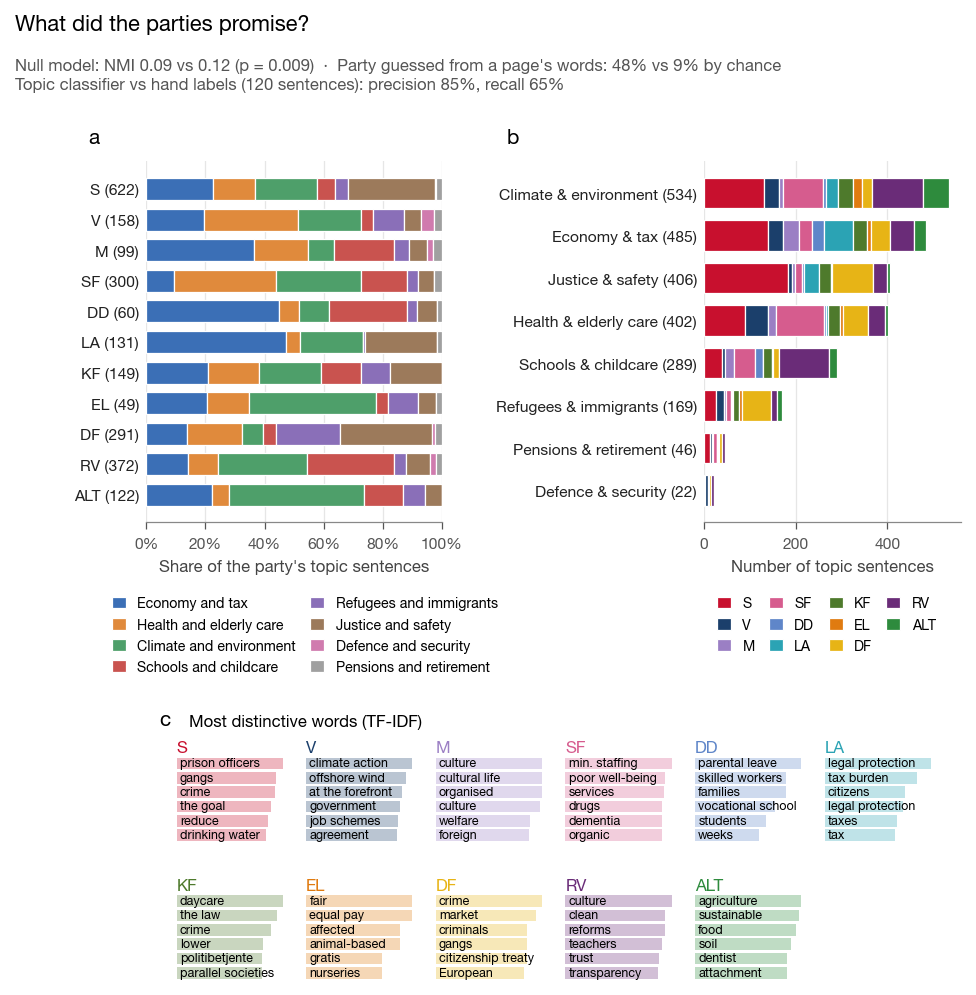

In [69]:
# --- FIGUR 1 · Hvad lovede partierne? (ny stil + validering) ---
# Indsæt i fig1_hvad_lover_de.ipynb (nye data, NB droppet) i stedet for "Saml figur 1"-cellen. Kræver stil.py i notebooks/.
import re, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import normalized_mutual_info_score as nmi
sys.path.append("..")
from stil import *

DATA = "../../data/"
# Nye data: én række pr. sætning (og pr. emne, hvis sætningen har flere). NB er droppet.
raa = pd.read_csv(DATA + "maerkesager_klassificeret.csv", encoding="utf-8-sig")
raa = raa[raa["party_code"].isin(PARTIER)]
sider = raa.drop_duplicates("document_id")[["document_id", "party_code", "text"]].reset_index(drop=True)   # 84 sider til TF-IDF
pol = raa[raa["kategori"].map(EMNE_EN).notna()].copy()                                                    # emne-sætninger ("Andet" ude)
pol["emne"] = pol["kategori"].map(EMNE_EN)
antal_saet = pol["party_code"].value_counts()
haand = pd.read_csv(DATA + "policy_validation_summary.csv").iloc[0]                                       # jeres håndkodning (120 sætninger)

# 1. Stopord og TF-IDF (samme som før)
custom_stopwords = [
    # Journalist- og citatord
    "sige", "mene", "udtale", "spørge", "svare", "fortælle", "kalde", "pege",
    # Talesprogs-fyldord
    "helt", "rigtig", "faktisk", "selvfølgelig", "god", "godt", "stor", "stort",
    "hel", "få", "gå", "tage", "se", "give", "komme", "blive", "gøre", "kunne",
    "ville", "skulle", "måtte", "når", "hvor", "hvordan", "fordi", "også", "bare",
    "lidt", "meget", "mange", "flere", "ny", "nyt", "nye", "dansk", "danmark",
    "parti", "partier", "politik", "politisk", "valgkamp", "valg", "folketingsvalg",
    "folk", "ting", "sag", "måde", "dag", "år", "gang", "tid", "del", "spørgsmål",
    "mette", "frederiksen", "lars", "løkke", "rasmussen", "jakob", "ellemann",
    "jensen", "søren", "pape", "poulsen", "pia", "olsen", "dyhr", "inger", "støjberg",
    "alex", "vanopslagh", "sofie", "carsten", "nielsen", "mai", "villadsen",
    "morten", "messerschmidt", "pernille", "vermund", "franciska", "rosenkilde"
]

smaaord = """og i at det en den til er som på de med han af for ikke der var mig sig men et har om vi
min havde ham hun nu over da fra du ud sin dem os op man hans hvor eller hvad skal selv her alle vil
blev kunne ind når være dog noget ville jo deres efter ned skulle denne end dette mit også under have
dig anden hende mine alt meget sit sine vor mod disse hvis din nogle hos blive mange ad bliver hendes
været thi jer sådan vores flere kan får gøre mere mindre derfor både hele sammen igennem uden andre
andet ved fordi danskerne""".split()

# Talord, fyldord og partinavne, som checket i afsnit 9 viste dominerer uden at sige noget om indholdet
ekstra = ["mio", "mia", "pct", "kr", "støtte", "stop", "giv", "ligeledes", "forskellige", "generelt",
          "socialdemokratiet", "venstre", "moderaterne", "enhedslisten", "alternativet", "radikale",
          "folkeparti", "danmarksdemokraterne", "konservative", "liberal", "alliance", "christiansborg",
          "nødt", "rigtigt", "sættes", "politikområder", "mærkesager", "ordfører", "foreslå", "læs",
          "indgået", "forslaget", "ugers", "virkeligheden", "nej", "pas", "tjener",
          "nyhedsbrev", "tilmeld", "bliv"]                      # hjemmeside-tekst ("tilmeld dig vores nyhedsbrev")

STOPORD = set(smaaord) | set(custom_stopwords) | set(ekstra)


def tokenize(tekst):
    ord_ = re.findall(r"[a-zæøåé]+", tekst.lower())
    return [w for w in ord_ if len(w) > 2 and w not in STOPORD]

docs = sider.groupby("party_code")["text"].apply(" ".join).reindex(PARTIER)
vec = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None, min_df=2, max_df=0.9, sublinear_tf=True)
X = vec.fit_transform(docs)
ORD = np.array(vec.get_feature_names_out())
WORD_TRANSLATIONS = {
    "fængselsbetjente": "prison officers",
    "bandernes": "gangs",
    "banderne": "gangs",
    "kriminalitet": "crime",
    "målet": "the goal",
    "nedbringe": "reduce",
    "drikkevand": "drinking water",
    "klimakampen": "climate action",
    "havvind": "offshore wind",
    "forrest": "at the forefront",
    "regeringen": "government",
    "beskæftigelsesindsats": "job schemes",
    "aftale": "agreement",
    "organiseret": "organised",
    "kulturen": "culture",
    "kultur": "culture",
    "velfærden": "welfare",
    "udenlandsk": "foreign",
    "skat": "tax",
    "minimumsnormeringer": "min. staffing",
    "mistrivsel": "poor well-being",
    "tilbud": "services",
    "demens": "dementia",
    "stoffer": "drugs",
    "økologisk": "organic",
    "barsel": "parental leave",
    "faglært": "skilled workers",
    "familierne": "families",
    "erhvervsskolerne": "vocational school",
    "studerende": "students",
    "elafgiften": "electricity tax",
    "retssikkerheden": "legal protection",
    "skattetryk": "tax burden",
    "borgerne": "citizens",
    "retssikkerhed": "legal protection",
    "skatter": "taxes",
    "dagtilbud": "daycare",
    "loven": "the law",
    "lavere": "lower",
    "praktiserende": "GPs",
    "flyttes": "relocated",
    "fair": "fair",
    "ligeløn": "equal pay",
    "ramt": "affected",
    "animalske": "animal-based",
    "hullerne": "the gaps",
    "sæt": "set",
    "reformer": "reforms",
    "rent": "clean",
    "lærere": "teachers",
    "tilliden": "trust",
    "åbenhed": "transparency",
    "landbrug": "agriculture",
    "bæredygtige": "sustainable",
    "mad": "food",
    "jord": "soil",
    "landbrugsjord": "agricultural land",
    "regenerativt": "regenerative",
    "kriminelle": "criminals",
    "marked": "market",
    "statsborgerretskonventionen": "citizenship treaty",
    "europæiske": "European",
    "uger": "weeks", "unødvendigt": "unnecessary", "vuggestuer": "nurseries",
    "videregående": "higher education", "tilknytning": "attachment",
    "kulturlivet": "cultural life", "arbejdsliv": "working life", "inflationen": "inflation",
    "modtagecenter": "reception centre", "fleksible": "flexible", "kæledyr": "pets",
    "fossilbiler": "fossil cars", "arbejdsforhold": "working conditions", "tandlæge": "dentist",
    "parallelsamfund": "parallel societies",
    "politibetjent": "police officers"
}



def top_ord(p, n=6):
    r = X[PARTIER.index(p)].toarray().ravel()
    idx = np.argsort(r)[::-1][:n]
    return [WORD_TRANSLATIONS.get(ORD[i], ORD[i]) for i in idx], r[idx] / r[idx].max()

# 2. VALIDERING A (uge 2): bland partinavnene mellem de 84 sider 1000 gange (sætninger på samme side følges ad)
rng = np.random.default_rng(0)
side_parti = sider.set_index("document_id")["party_code"]
nmi_rigtig = nmi(pol["party_code"], pol["emne"])
def bland():
    ny = pd.Series(rng.permutation(side_parti.values), index=side_parti.index)
    return nmi(pol["document_id"].map(ny), pol["emne"])
nmi_null = np.array([bland() for _ in range(1000)])
p_nmi = p_vaerdi(nmi_rigtig, nmi_null, "lavere")

# 3. VALIDERING B (uge 6): gæt partiet ud fra én sides ord (tag siden ud, byg TF-IDF på resten)
def gaet_parti(partier):
    rigtige = 0
    for i in range(len(sider)):
        maske = np.arange(len(sider)) != i
        dok = pd.Series(sider["text"].values[maske]).groupby(partier[maske]).apply(" ".join)
        v = TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None, min_df=2, max_df=0.9, sublinear_tf=True)
        D = v.fit_transform(dok)
        rigtige += dok.index[cosine_similarity(v.transform([sider["text"][i]]), D).argmax()] == partier[i]
    return rigtige / len(sider)

acc = gaet_parti(sider["party_code"].values)
acc_null = np.mean([gaet_parti(rng.permutation(sider["party_code"].values)) for _ in range(30)])    # ca. 1 min
print(f"Håndkodning: precision {haand['micro_precision']:.0%}, recall {haand['micro_recall']:.0%} (n = {int(haand['n_segments'])})")
print(f"NMI = {nmi_rigtig:.2f}, null {nmi_null.mean():.2f}, {p_tekst(p_nmi)} | gætteleg {acc:.0%}, blandet {acc_null:.0%}, gætning {1 / len(PARTIER):.0%}")

# 4. Tegn: øverst a (emner pr. parti) og b (partier pr. emne); nederst c (ord pr. parti)
fig = plt.figure(figsize=(BREDDE, 18 * CM))
ydre = fig.add_gridspec(2, 1, height_ratios=[1, 0.62], hspace=0.8)
top = ydre[0].subgridspec(1, 2, width_ratios=[1.15, 1], wspace=0.95)
ax, bx = fig.add_subplot(top[0]), fig.add_subplot(top[1])

andel = pd.crosstab(pol["party_code"], pol["emne"], normalize="index").reindex(index=PARTIER, columns=EMNE_ORDEN, fill_value=0)
brugte = [t for t in EMNE_ORDEN if andel[t].sum() > 0]
venstre = np.zeros(len(PARTIER))
for t in brugte:
    v = andel[t].values
    ax.barh(range(len(PARTIER)), v, left=venstre, color=EMNE_FARVE[t], height=0.72, edgecolor="white", linewidth=0.6, label=t)
    venstre += v
ax.set_yticks(range(len(PARTIER)), [f"{p} ({antal_saet[p]})" for p in PARTIER])
ax.invert_yaxis(); ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Share of the party's topic sentences")
panel(ax, "a", x=-0.16)
ax.legend(ncol=2, loc="upper left", bbox_to_anchor=(-0.16, -0.17), fontsize=6.8)

ant = pd.crosstab(pol["emne"], pol["party_code"]).reindex(columns=PARTIER, fill_value=0)
ant = ant.loc[ant.sum(axis=1).sort_values().index]
venstre = np.zeros(len(ant))
for p in PARTIER:
    bx.barh(range(len(ant)), ant[p].values, left=venstre, color=PARTI_FARVE[p], height=0.72, edgecolor="white", linewidth=0.6, label=p)
    venstre += ant[p].values
bx.set_yticks(range(len(ant)), [f"{t.replace(' and ', ' & ')} ({int(ant.loc[t].sum())})" for t in ant.index])
bx.set_xlabel("Number of topic sentences")
panel(bx, "b", x=-0.72)
bx.legend(ncol=4, loc="upper left", bbox_to_anchor=(0.0, -0.17), fontsize=6.8)

midt = ydre[1].subgridspec(1, 3, width_ratios=[0.04, 1, 0.04], wspace=0)[1]          # centrér ordene
ordgitter = midt.subgridspec(2, 6, hspace=0.6, wspace=0.22)
for k, p in enumerate(PARTIER):
    cx = fig.add_subplot(ordgitter[k // 6, k % 6])
    ord_, vaegt = top_ord(p)
    cx.barh(range(len(ord_)), vaegt, color=PARTI_FARVE[p], alpha=0.3, height=0.82)
    for i, w in enumerate(ord_):
        cx.text(0.03, i, w, va="center", ha="left", fontsize=6)
    cx.set_xlim(0, 1); cx.set_ylim(len(ord_) - 0.5, -0.5)
    cx.set_xticks([]); cx.set_yticks([]); cx.grid(False)
    cx.spines[["bottom"]].set_visible(False)
    cx.set_title(p, fontsize=8, fontweight="bold", color=PARTI_FARVE[p], loc="left", pad=2)
    if k == 0:
        panel(cx, "c", x=-0.06, y=1.32)
        cx.text(0.12, 1.32, "Most distinctive words (TF-IDF)", transform=cx.transAxes, fontsize=8, va="bottom")
fig.add_subplot(ordgitter[1, 5]).axis("off")

titel(fig, "What did the parties promise?",
      f"Null model: NMI {nmi_rigtig:.2f} vs {nmi_null.mean():.2f} ({p_tekst(p_nmi)})  ·  Party guessed from a page's words: {acc:.0%} vs {1 / len(PARTIER):.0%} by chance\n"
      f"Topic classifier vs hand labels ({int(haand['n_segments'])} sentences): precision {haand['micro_precision']:.0%}, recall {haand['micro_recall']:.0%}", y=0.935)
gem(fig, "fig1_hvad_lover_de")
plt.show()

## 11 · Tabel over mærkesager til Methods eller appendiks

In [ ]:
tabel = (pol.sort_values(["party_code", "kategori"])
            .groupby("party_code")
            .agg(antal=("title", "size"), maerkesager=("title", lambda t: "; ".join(t)))
            .reindex(PARTIER))
tabel.to_csv("tabel_maerkesager.csv", encoding="utf-8-sig")
print(tabel.to_string()[:3000])

            antal                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

## 12 · Til captionen

Udfyld tallene i [klammer]:

*What the parties promised. (a) Share of each party's pre-election policy pages by policy area (Internet Archive captures ≤ 31 Oct 2022; n = [83] pages, number per party in brackets). (b) The six terms with the highest TF-IDF weight in each party's pages, i.e. terms the party uses often and few other parties use. Danish stopwords, numerals and party names removed.*

Panel c, hvis den kommer med: *Text network: each party is linked to its three most similar parties (TF-IDF cosine); edge width shows similarity. V and M are both linked to S but not to each other. [19] of the 27 edges remain for k = 2, and all remain for k = 4.*